# 01 — lfast_etc as an exposure time calculator

`lfast_etc` is the exposure time calculator (ETC) for **LFAST**, an array of small telescopes at
Kitt Peak: nominally 20 units of 0.726 m, each feeding an 18 um fiber, with the fibers merged into
one spectrograph input by a fiber combiner. Two spectrographs are modelled: the **WIYN Bench**
(visible, 15 grating/order modes) and **CSHELL** (near-infrared, 1.08 to 1.75 um, R up to 43,000).
The throughput model follows Choi et al. (2026, SPIE 14147). The question it answers is *"how long
do I need to expose to reach a given signal-to-noise ratio (SNR) on this target, and what SNR do I
get in a given time?"*

A **web version** of the same calculator, with the same presets and sky, is at
<https://simulators.schmidtobservatorysystem.org/lfast/>: use it for a quick number, and these
notebooks when you want sweeps, plots and your own spectra.

**One idea to hold on to: everything is per resolution element.** The spectrum is cut into bins
one resolution element (resel) wide, $\delta\lambda = \lambda/R$. In each bin the source delivers
$N_*$ electrons per second (summed over the array), the sky $N_{sky}$ electrons per second per pixel,
and the resel is spread over $n_{pix}$ detector pixels. With dark current $D$, read noise $RN$ and a
total exposure $t$ split into $n_{exp}$ reads,

$$\mathrm{SNR} = \frac{N_* t}{\sqrt{N_* t + n_{pix}(N_{sky} + D)\,t + n_{pix}\, n_{exp}\, RN^2}}.$$

Survey papers often quote SNR per pixel, which is lower by about $\sqrt{2.2}$ on the Bench
(the pixels per resel along the dispersion direction): SNR 30 per resel is roughly SNR 20 per pixel.

In this notebook:
1. an ETC: `LFASTETC(preset, n_telescopes)`,
2. a source: `Source.blackbody()`,
3. exposure time for an SNR, and SNR for an exposure time: `exptime()` and `snr()`,
4. reading the result: `plot()`, `summary()`, `at()`, `to_table()`, `plot_spectrum()`.

**Jupyter AI.** These notebooks are written to be run with the Jupyter AI chat open in the side
panel (the sparkle icon). Boxes marked 🤖 suggest things to ask it. It can see the cell you have
selected, so "explain this cell" or pasting a traceback works well. Boxes marked ✏️ ask you to guess
a number before computing it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

***
## 1. An ETC

An `LFASTETC` is an instrument preset plus a telescope array plus a sky model. The presets are
TOML files inside the package (notebook 02 lists them); `bench_r1800` is the Bench sample
configuration at R ~ 1800 over 412 to 686 nm. Printing the object tells you what you built:
resolving power, bandpass, pixels per resel, detector numbers, the array, and the sky table.

In [2]:
etc = LFASTETC("bench_r1800", n_telescopes=20)
etc

LFASTETC(bench_r1800: R=1800, 412-686 nm, 2.2x2.2 pix/resel (tophat), S_opt=0.3, slit=1.0, RN=3.7 e-, dark=0.0003 e-/s/pix | 20 x 0.726 m telescopes (total area 8.28 m^2, 3.2 m equivalent), 18um fiber (1.48" on sky), combine=fiber, 1 input(s) | SkyCalc table skytable_secz1.3.fits x 1 | gaussian LSF, 8x oversampled pixels, 918 bins)

The wavelength grid has one point per resel, about 900 bins between 412 and 686 nm. The preset
stops at 686 nm because the telescope throughput curve has a zero at the 687 nm O$_2$ band.

***
## 2. A source

A `Source` is a spectral shape plus one magnitude in one band. The magnitude sets the absolute
scale; the shape comes from a blackbody, a power law, a flat spectrum or your own arrays
(notebook 03). Here: a 5800 K star at V = 15 (Vega), with a 30% deep H$\alpha$ line added.

blackbody 5800 K, V=15.00 (Vega) | synthetic J = 13.85


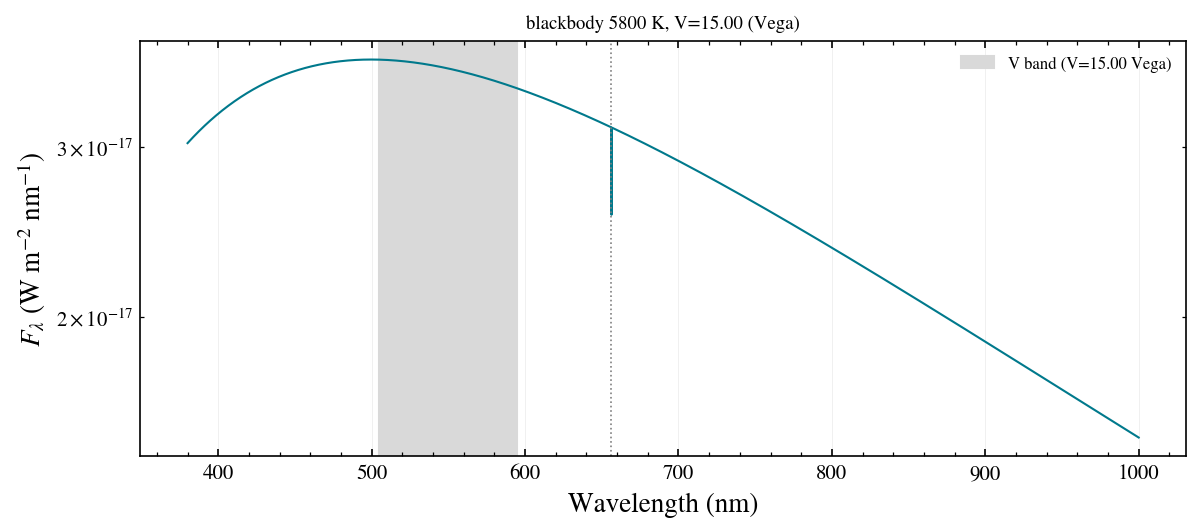

In [3]:
src = Source.blackbody(5800, mag=15, band="V").add_line(656.3, depth=0.3, sigma_nm=0.05)
print(src.describe(), "| synthetic J =", round(src.magnitude("J"), 2))
src.plot(wavelength_nm=np.linspace(380, 1000, 2000));

The shaded box is the normalising band. The synthetic J magnitude comes from integrating the same
spectrum over the J band, which is how you get a magnitude in another band for a target you only
know in one.

***
## 3. Exposure time for an SNR

`exptime(source, snr)` returns an `ETCResult` with one value per bin. The plot shows the total
exposure time needed for SNR 50 per resel at each wavelength. Time rises steeply to the blue because
both the throughput and this star's spectrum fall there, and the H$\alpha$ line shows up as a
spike: fewer photons in the line, more time needed.

{'snr': {10: 50.0, 50: 50.0, 90: 50.0},
 'exptime': {10: 233.08570785490699,
  50: 366.51929002940756,
  90: 937.3662421754574},
 'saturated_fraction': 0.0,
 'below_min_exptime_fraction': 0.0,
 'n_bins': 918}

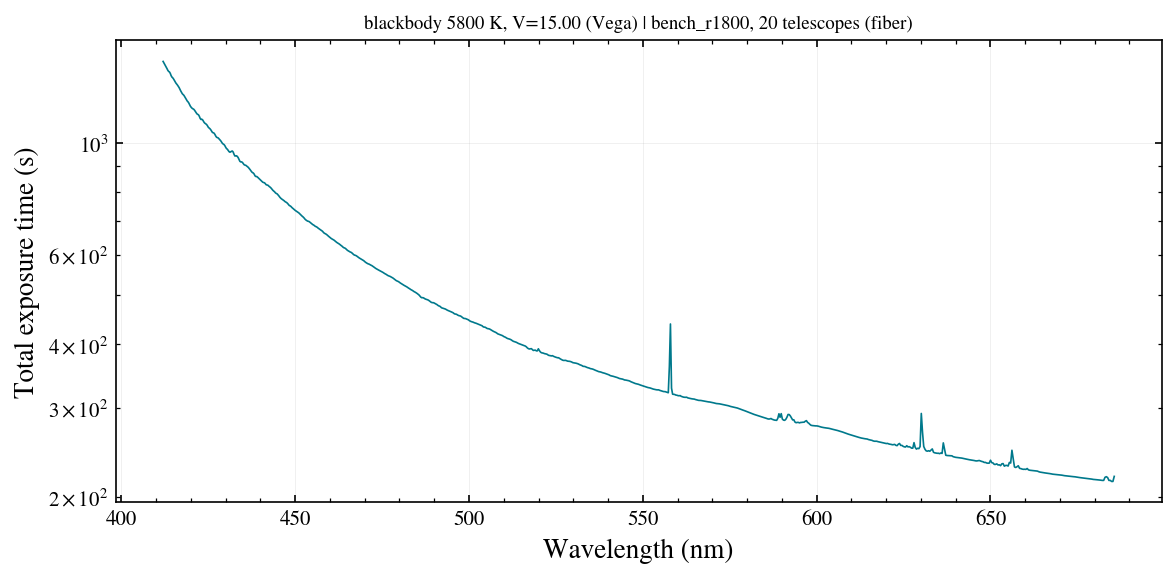

In [4]:
res = etc.exptime(src, snr=50)
res.plot()
res.summary()

`summary()` gives the 10th, 50th and 90th percentiles over the band. The median is the number to
quote if you need one exposure time for the whole spectrum. Pick one wavelength with `at`, or export
every column to an astropy table (`to_table().write("spectrum.csv")` for a file).

In [5]:
print(res.at(550.0))
res.to_table()[:5]

{'snr': 50.0, 'exptime': 331.3395310096607, 'n_star': 7.942516150602066, 'n_sky_pix': 0.044811109447126, 'peak_e_per_pixel': 674.7581960938048}


wavelength,delta_lambda,snr,exptime,n_star,n_sky_pix,peak_e_per_pixel,saturated,below_min_exptime
float64,float64,float64,float64,float64,float64,float64,bool,bool
412.0,0.2288888888888889,50.0,1449.9401521558743,1.8545210545985134,0.01921704319574052,705.1074646640993,False,False
412.22888888888895,0.22901604938271608,50.0,1440.4818303824436,1.8653736664000293,0.01903042218062925,704.0843536271354,False,False
412.45790493827167,0.22914328052126204,50.0,1431.6803506239219,1.8762429097972202,0.01900715724479804,703.6253769400829,False,False
412.68704821879294,0.22927058234377384,50.0,1422.5391498304953,1.8871567124435185,0.01886007369905506,702.7543533713341,False,False
412.9163188011368,0.22939795488952044,50.0,1413.0942667677223,1.898102742330929,0.018593091659597116,701.4927168942852,False,False


> ✏️ **Before you run the next cell:** the median time for SNR 50 is in the summary above. For SNR 100, is it twice as long, four times, or ten times? Write your guess down (or put it in the room poll), then run.

In [6]:
for snr in (25, 50, 100):
    t = etc.exptime(src, snr=snr)
    print(f"SNR {snr:3d}: median {t.summary()['exptime'][50]:7.1f} s, at 550 nm {t.at(550.0)['exptime']:7.1f} s")

SNR  25: median    97.6 s, at 550 nm    88.3 s
SNR  50: median   366.5 s, at 550 nm   331.3 s
SNR 100: median  1440.0 s, at 550 nm  1301.7 s


Four times, not two: $\mathrm{SNR} \propto \sqrt{t}$ when the star's own photon noise dominates.
Notebook 03 shows where that stops being true.

***
## 4. SNR for an exposure time

The inverse question. The dashed line marks SNR 50, so you can see where a 600 s exposure reaches
the target set above. `n_exp` splits the total time into reads, each paying its read noise
(notebook 03).

{10: 39.743436160146345, 50: 64.2719849675041, 90: 80.81555593419124}

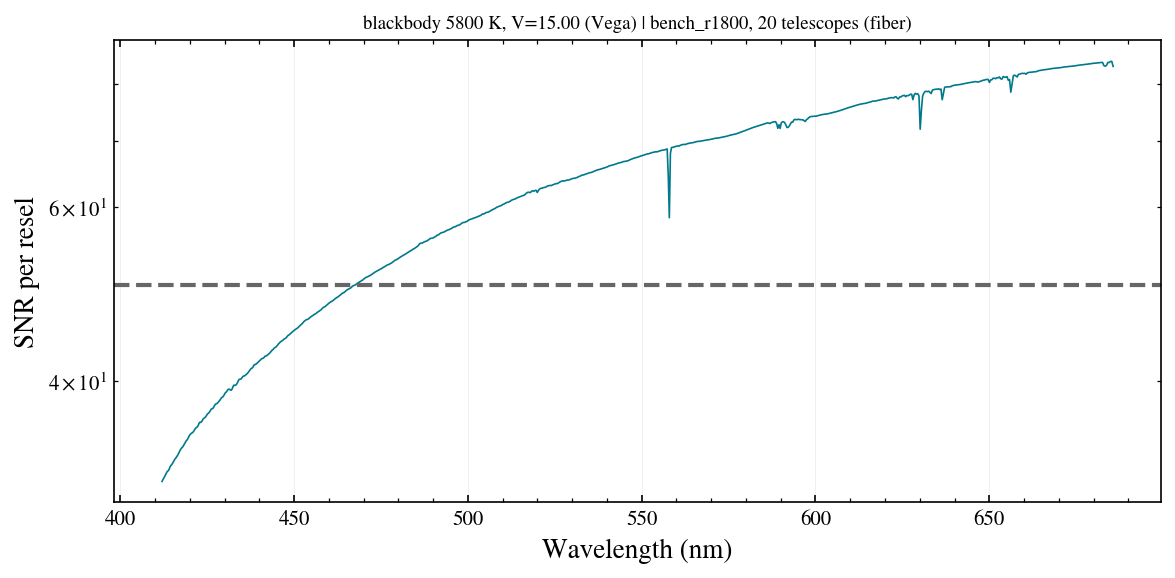

In [7]:
res = etc.snr(src, exptime=600)
ax = res.plot()
ax.axhline(50, color="0.4", ls="--")
res.summary()["snr"]

`simulate` draws one realisation of the extracted spectrum with the per-resel SNR of the result,
and `plot_spectrum` overlays it on the noiseless signal. The H$\alpha$ dip is clearly detected at
this SNR. This is the plot to show when someone asks whether a feature will be visible.

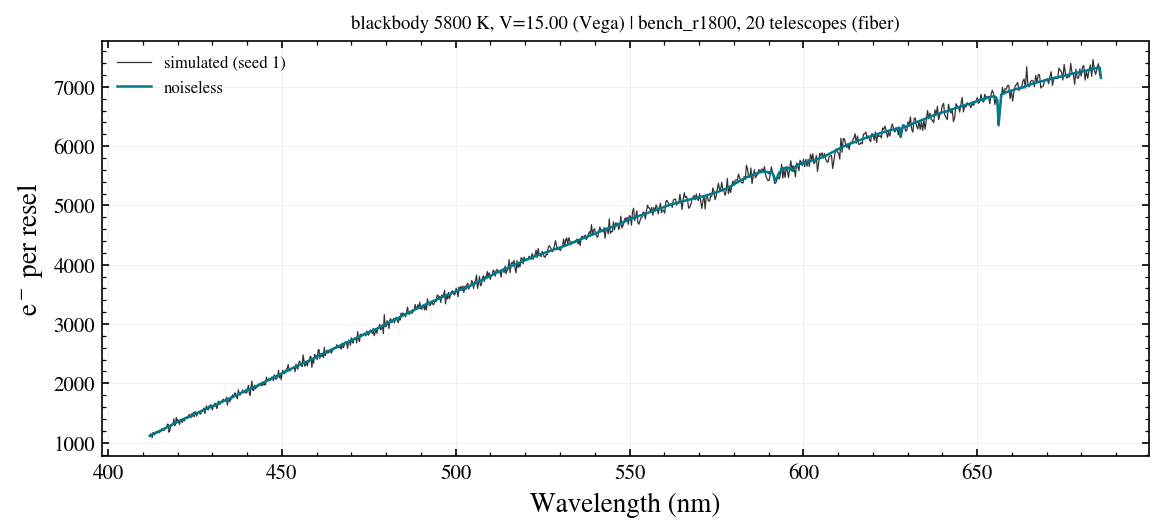

In [8]:
res.plot_spectrum(seed=1);

> 🤖 **Ask Jupyter AI:** *Loop over V = 12 to 20 in steps of 1 for this star and print the median exposure time for SNR 30 per resel in a table, with the time in minutes.*
>
> Then ask it why the step from V = 18 to 19 costs more than a factor 2.5.

***
## 5. Check yourself

The round trip must close: the SNR computed for the exposure times that `exptime` returned has to
be the target SNR in every bin. If this fails, something in your installation is off.

In [9]:
t = etc.exptime(src, snr=50)
back = etc.snr(src, exptime=t.exptime)
assert np.allclose(back.snr[np.isfinite(back.snr)], 50, rtol=1e-8)
print("round trip OK")

round trip OK


***
## Summary

```python
etc = LFASTETC("bench_r1800", n_telescopes=20)        # preset + array (+ default grey-time sky)
src = Source.blackbody(5800, mag=15, band="V")         # shape + one magnitude in one band
res = etc.exptime(src, snr=50)                        # time per resel for SNR 50
res = etc.snr(src, exptime=600, n_exp=1)              # SNR per resel in 600 s
res.plot(); res.summary(); res.at(550.0); res.to_table(); res.plot_spectrum()
```

Next: [02 — instruments, presets and the array](02_instruments_presets_array.ipynb).